In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import math

from scipy.stats import norm
sns.set(style='whitegrid', font_scale=1.3, palette='Set2')

# Задача 1. Равномерное vs экспоненциальное распределение

Пусть $X$ — наблюдение, которое принимает неотрицательные значения.

Основная гипотеза $H_0$ состоит в том, что $X$ имеет равномерное распределение на отрезке $[0;1]$, альтернатива $H_1$ в том, что $X$ имеет экспоненциальное распределение с параметром 1.

Построй наиболее мощный критерий уровня значимости $\alpha = 0.05$ для проверки гипотез $H_0$ против $H_1$.

**Решение**

Имеем такие гипотезы:

$$H_0: X \sim U[0; 1]$$

$$H_1: X \sim Exp(1)$$


Перепишем задачу нахождения "оптимального" критерия, на формальном языке:


$$
 \begin{cases}
   \mathbb{P}(I_S) \leq \alpha \\
   \mathbb{P}(II_S) \rightarrow min
 \end{cases}
$$

 - $\mathbb{P}(I_S)$ – вероятность ошибки первого рода;
 - $\mathbb{P}(II_S)$ – вероятность ошибки второго рода.

При этом, критерий можно задать с помощью множества $S$.

$X \in S $ тогда и только тогда, когда мы отвергаем гипотезу $H_0$.

Тогда в рамках этих обозначений и условия задачи, запишем математическую формулировку задачи снова:


$$
 \begin{cases}
   \mathbb{P}(I_S) = P_{U[0;1]} (X \in S) \leq \alpha \\
   \mathbb{P}(II_S) = P_{exp(1)}(X \notin S) \rightarrow min
 \end{cases}
$$



В свою очередь, вероятность множества $S$ - это длина отрезков, составляющих это множество.

Более формально – мера Лебега на отрезке $[0;1]$ этого множества

А для $\mathbb{P}(II_S)$ это площадь под графиком функции $e^{-x}$.

In [2]:
from scipy.stats import expon, uniform

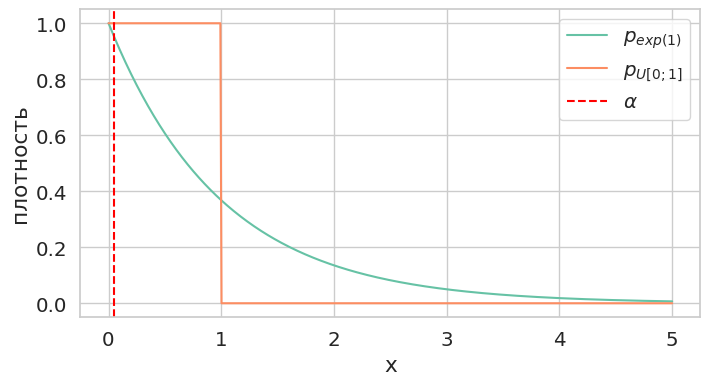

In [3]:
p_exp = expon(scale=1).pdf
p_uniform = uniform(loc=0, scale=1).pdf

grid = np.linspace(0, 5, 500)
plt.figure(figsize=(8, 4))

plt.plot(grid, p_exp(grid), label='$p_{exp(1)}$')
plt.plot(grid, p_uniform(grid), label='$p_{U[0;1]}$')
plt.axvline(x=0.05, label=r'$\alpha$', c='r', ls='--')
plt.xlabel('x')
plt.ylabel('плотность')

plt.legend()
plt.show()

Так как функция $e^{-x}$ убывает, то имеет смысл брать в множество-критерий отрезок $[0; \alpha]$, чтобы минимизировать вероятность ошибки второго рода при фиксированной вероятности ошибки первого рода.

Общий вид множества: $S = [0; \alpha] \cup [1; +\infty)$

Тогда ошибкой второго рода будет:

$$P(II_S) = P_{exp(1)}(X \notin S) = \int_{\alpha}^1 e^{-x}dx \approx 0,583$$

# Задача 2. Проверка честности игрального кубика

Производитель настольных игр проверяет качество игральных кубиков. Известно, что некоторые кубики имеют дефект: вероятность выпадения шестёрки у них повышена.

Для проверки кубик бросают **10 раз**. Пусть $X$ — количество выпавших шестёрок.

Рассматриваются две гипотезы:

$$H_0: X \sim Bin(10, 1/6)$$

$$H_1: X \sim Bin(10, 1/2)$$

То есть при $H_0$ кубик честный, а при $H_1$ шестёрка выпадает с вероятностью $0.5$.

**Задания:**

1. Запишите вероятности $P(X=k)$ при обеих гипотезах.
2. Постройте графики функций вероятностей двух распределений.
3. Определите, при каких значениях $X$ следует отвергать $H_0$.
4. Постройте наиболее мощный нерандомизированный критерий уровня значимости не более $\alpha=0.05$.
5. Вычислите вероятность ошибки второго рода и мощность критерия.
6. Проверьте полученные результаты методом Монте-Карло.

In [5]:
from scipy.stats import binom

In [6]:
n = 10
p0 = 1 / 6
p1 = 1 / 2
alpha = 0.05

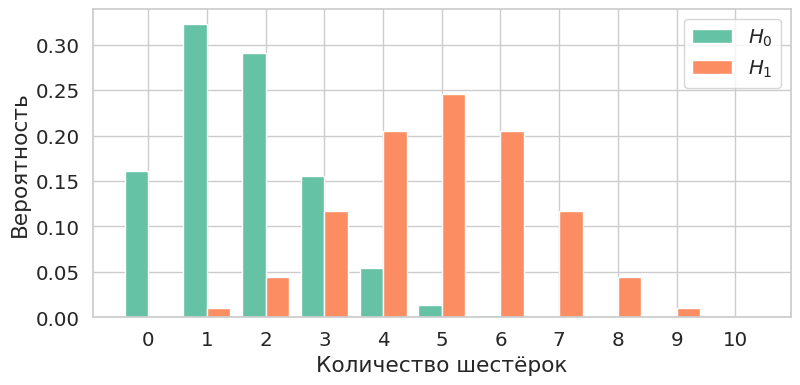

In [7]:
k = np.arange(n + 1)

plt.figure(figsize=(9, 4))
plt.bar(k - 0.2, binom.pmf(k, n, p0), width=0.4, label='$H_0$')
plt.bar(k + 0.2, binom.pmf(k, n, p1), width=0.4, label='$H_1$')
plt.xlabel('Количество шестёрок')
plt.ylabel('Вероятность')
plt.xticks(k)
plt.legend()
plt.show()

**Решение**

При $H_0$ вероятность шестёрки равна $1/6$, а при $H_1$ — $1/2$.

Вероятности получить ровно $k$ шестёрок:

$$P_0(X=k)=C_{10}^k(1/6)^k(5/6)^{10-k}$$

$$P_1(X=k)=C_{10}^k(1/2)^k(1/2)^{10-k}=C_{10}^k(1/2)^{10}$$

Сравним вероятности одного и того же результата при двух гипотезах:

$$\frac{P_1(X=k)}{P_0(X=k)}=\frac{C_{10}^k(1/2)^{10}}{C_{10}^k(1/6)^k(5/6)^{10-k}}=\frac{3^{10}}{5^{10-k}}$$

Это отношение возрастает с ростом $k$.

По лемме Неймана — Пирсона наиболее мощный критерий должен отвергать $H_0$ при достаточно больших значениях $X$.

Таким образом, критическую область ищем в виде:

$$S=\{k:k\ge c\}$$

Вероятность ошибки первого рода — вероятность отвергнуть $H_0$, когда она верна:

$$P(I_S)=P_0(X\in S)\leq\alpha=0.05$$

Проверим несколько вариантов критической области.

Если отвергать $H_0$ при $X\geq4$, то:

$$P_0(X\geq4)=\sum_{k=4}^{10}C_{10}^k(1/6)^k(5/6)^{10-k}\approx0.0697$$

Это больше допустимого уровня значимости.

Если отвергать $H_0$ при $X\geq5$, то:

$$P_0(X\geq5)=\sum_{k=5}^{10}C_{10}^k(1/6)^k(5/6)^{10-k}\approx0.0155$$

Условие выполняется. Следовательно, выбираем критическую область:

$$\boxed{S=\{5,6,7,8,9,10\}}$$

То есть отвергаем гипотезу о честности кубика, если за 10 бросков шестёрка выпала хотя бы 5 раз.

In [8]:
for c in range(3, 7):
    p_error = binom.sf(c - 1, n, p0)
    print(f'X >= {c}: P(I) = {p_error:.4f}')

X >= 3: P(I) = 0.2248
X >= 4: P(I) = 0.0697
X >= 5: P(I) = 0.0155
X >= 6: P(I) = 0.0024


Ошибка второго рода возникает, когда кубик неисправен, но мы не отвергаем $H_0$.

Для нашего критерия это означает, что при $H_1$ выпало меньше пяти шестёрок:

$$P(II_S)=P_1(X<5)=\sum_{k=0}^{4}C_{10}^k(1/2)^{10}$$

$$\boxed{P(II_S)\approx0.377}$$

Мощность критерия — вероятность обнаружить неисправный кубик, когда он действительно неисправен:

$$Power=1-P(II_S)\approx0.623$$

**Вывод:** построенный критерий обнаруживает неисправный кубик примерно в $62.3\%$ случаев. При этом вероятность ошибочно объявить исправный кубик неисправным составляет около $1.55\%$.

Фактический уровень значимости меньше $5\%$. Это связано с дискретностью биномиального распределения: мы не можем выбрать критическую область вида $X\geq c$, вероятность которой в точности равна $0.05$.

In [9]:
c = 5

error_1 = binom.sf(c - 1, n, p0)
error_2 = binom.cdf(c - 1, n, p1)
power = 1 - error_2

print(f'Ошибка первого рода: {error_1:.4f}')
print(f'Ошибка второго рода: {error_2:.4f}')
print(f'Мощность критерия: {power:.4f}')

Ошибка первого рода: 0.0155
Ошибка второго рода: 0.3770
Мощность критерия: 0.6230


**Численная проверка методом Монте-Карло**

Проверим полученные вероятности с помощью моделирования.

Проведём $100\,000$ независимых экспериментов для каждой гипотезы. В каждом эксперименте будем моделировать 10 бросков кубика и подсчитывать количество шестёрок.

Для каждой гипотезы определим долю экспериментов, в которых $X\geq5$.

- При $H_0$ эта доля оценивает вероятность ошибки первого рода.
- При $H_1$ эта доля оценивает мощность критерия.
- Доля экспериментов при $H_1$, в которых $X<5$, оценивает вероятность ошибки второго рода.

Сравним полученные оценки с аналитическими результатами.

In [10]:
rng = np.random.default_rng(42)
N = 100_000

x0 = rng.binomial(n, p0, size=N)
x1 = rng.binomial(n, p1, size=N)

mc_error_1 = np.mean(x0 >= c)
mc_error_2 = np.mean(x1 < c)
mc_power = np.mean(x1 >= c)

print('                      Аналитически   Монте-Карло')
print(f'Ошибка первого рода:    {error_1:.4f}         {mc_error_1:.4f}')
print(f'Ошибка второго рода:    {error_2:.4f}         {mc_error_2:.4f}')
print(f'Мощность критерия:      {power:.4f}         {mc_power:.4f}')

                      Аналитически   Монте-Карло
Ошибка первого рода:    0.0155         0.0155
Ошибка второго рода:    0.3770         0.3781
Мощность критерия:      0.6230         0.6219


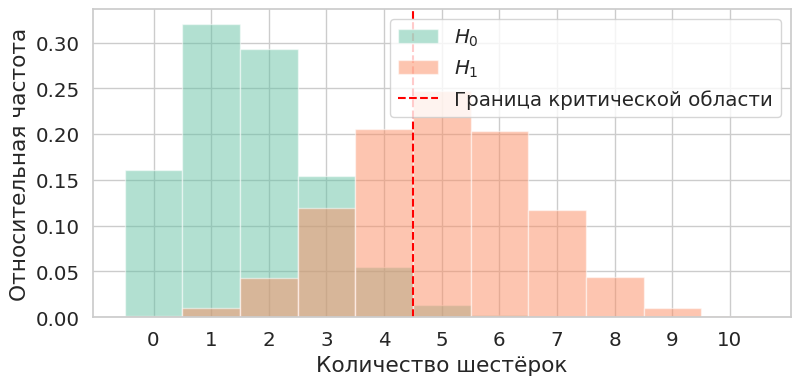

In [11]:
plt.figure(figsize=(9, 4))

plt.hist(x0, bins=np.arange(-0.5, 11.5, 1),
         density=True, alpha=0.5, label='$H_0$')

plt.hist(x1, bins=np.arange(-0.5, 11.5, 1),
         density=True, alpha=0.5, label='$H_1$')

plt.axvline(c - 0.5, color='red', ls='--', label='Граница критической области')

plt.xlabel('Количество шестёрок')
plt.ylabel('Относительная частота')
plt.xticks(range(11))
plt.legend()
plt.show()

**Вывод**

Аналитические вычисления и моделирование методом Монте-Карло дают близкие результаты.

При выбранной критической области $S=\{5,6,7,8,9,10\}$:

- вероятность ошибки первого рода составляет около $1.55\%$;
- вероятность ошибки второго рода составляет около $37.7\%$;
- мощность критерия составляет около $62.3\%$.

Метод Монте-Карло позволяет численно оценивать характеристики критерия, даже если аналитически вычислять вероятности сложно.

При увеличении числа экспериментов $N$ оценки Монте-Карло становятся стабильнее и приближаются к теоретическим вероятностям.